In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import glob
import json
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_context("talk")
pd.options.display.max_columns = None

In [11]:
import infostop
import pandas as pd
import utm
import numpy as np
import os
import glob
from datetime import datetime
from dataclasses import asdict
# pd.set_option('display.max_rows', None)

import util as bw_util

from scales_human_mobility.utils import scale_by_scale_optim
from scales_human_mobility.utils import compute_intervals
from scales_human_mobility.utils import scales_of_mobility
from scales_human_mobility.utils import scale_fitter_no_grid
from scales_human_mobility.utils import utils


FOLDER = "../results/movebank/"

START = 0
DOWNSAMPLE_RATE_MINUTES = [60]

STOP_RADII = [10, 30, 90]
LABEL_SINGLETON = [True]
DROP_IDENTICAL_LAT_LON = True



# Loads all the data using glob.glob.

movebank_csvs = glob.glob("../data/movebank/events/*.csv")


# Concat if needed:
all_csvs = movebank_csvs # private_csvs # private_csvs + movebank_csvs

In [131]:
speeds_by_species = {}

# Applies downsample rates and runs once for each of these.

for i in range(START, len(all_csvs)):
    df = pd.read_csv(all_csvs[i], low_memory=False)

    # There should only be one study id.
    if len(df) < 1 or "study_id" not in df.columns:
        continue
    assert(len(df["study_id"].unique()) == 1)
    study_id = df["study_id"].unique()[0]

    all_data = []

    SPECIES = df["species"].unique()


    
    for _species in SPECIES:

        if _species not in speeds_by_species:
            speeds_by_species[_species] = np.array([])

        df_species = df[df["species"] == _species]

        print(f"\r{i}/{len(movebank_csvs)} evaluating {study_id} {_species}")

        individuals = df_species["individual"].unique()
        
        num_to_run = min(len(individuals), 10)
        for j in range(num_to_run):
            _id = individuals[j]
            # This is just a fun little progress bar.
            print(f"\r[{'.' * (j + 1) + ' '*(num_to_run - (j + 1))}]", end="")

            df_individual = df_species[df_species["individual"] == _id]

            df_individual = df_species[df_species["individual"] == _id]

            for downsample_rate in DOWNSAMPLE_RATE_MINUTES:

                _df = bw_util.downsampled(df_individual, downsample_rate)
                if DROP_IDENTICAL_LAT_LON:
                    _df = bw_util.drop_identical_lat_lon(_df)
                
                _df = _df[['latitude','longitude','time']].dropna()
                _df = _df.sort_values(by = 'time').reset_index(drop = True)
    
                # Computes pairwise time intervals, in seconds.
                _times = _df.sort_values(by = 'time')["time"].to_numpy()
                intervals_seconds = (_times[1:] - _times[:-1])
    
                # Uses haversine formula in numpy to very quickly find distances between lat/long.
                # There are more accurate libraries, but this is generally best practice, and 
                # was already implemented by the scales of human mobility library.
                points = _df[['latitude', 'longitude']].to_numpy()
                distances_meters = utils.haversine(points[:-1], points[1:])
    
                speeds_ms = distances_meters / intervals_seconds
                speeds_by_species[_species] = np.append(speeds_by_species[_species], speeds_ms)



0/152 evaluating 10449535 Ciconia ciconia
1/152 evaluating 180290122 Thalassoica antarctica
2/152 evaluating 2630711281 Morus bassanus
3/152 evaluating 20873986 Haliaeetus leucocephalus
4/152 evaluating 1241071371 Vulpes lagopus
5/152 evaluating 6432602888 Somateria mollissima
5/152 evaluating 6432602888 Melanitta fusca
6/152 evaluating 182459847 Cygnus cygnus
7/152 evaluating 2944153255 Larus smithsonianus
8/152 evaluating 217784323 Cathartes aura
8/152 evaluating 217784323 Coragyps atratus
9/152 evaluating 3133580132 Lepus europaeus
10/152 evaluating 2398637362 Falco naumanni
11/152 evaluating 1426277950 Tyto furcata
12/152 evaluating 497091077 Anthropoides virgo
12/152 evaluating 497091077 Grus vipio
13/152 evaluating 278258431 Chroicocephalus ridibundus
14/152 evaluating 1480583194 Hydroprogne caspia
15/152 evaluating 259354593 Aquila chrysaetos
16/152 evaluating 268904527 Wallabia bicolor
17/152 evaluating 1728787796 Felis catus
18/152 evaluating 175963833 Columba livia
19/152 eva

In [135]:
rows = []
for key, speeds in speeds_by_species.items():
    row = {"species": key}
    for x in range(21):
        p = x*5
        try:
            row[f"{p}_percentile_step"] = np.percentile(speeds*60*60, p)
        except Exception as e:
            print(key, e)
    rows.append(row)

step_percentiles = pd.DataFrame(rows)
step_percentiles.to_csv("../results/percentile_steps_by_species.csv")

Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for axis 0 with size 0
Bassaricyon alleni index -1 is out of bounds for

In [79]:
distances_meters

array([ 143.89510417, 2111.25238699,  843.88726775, ...,  786.50531278,
        143.93868333, 1224.54512758])

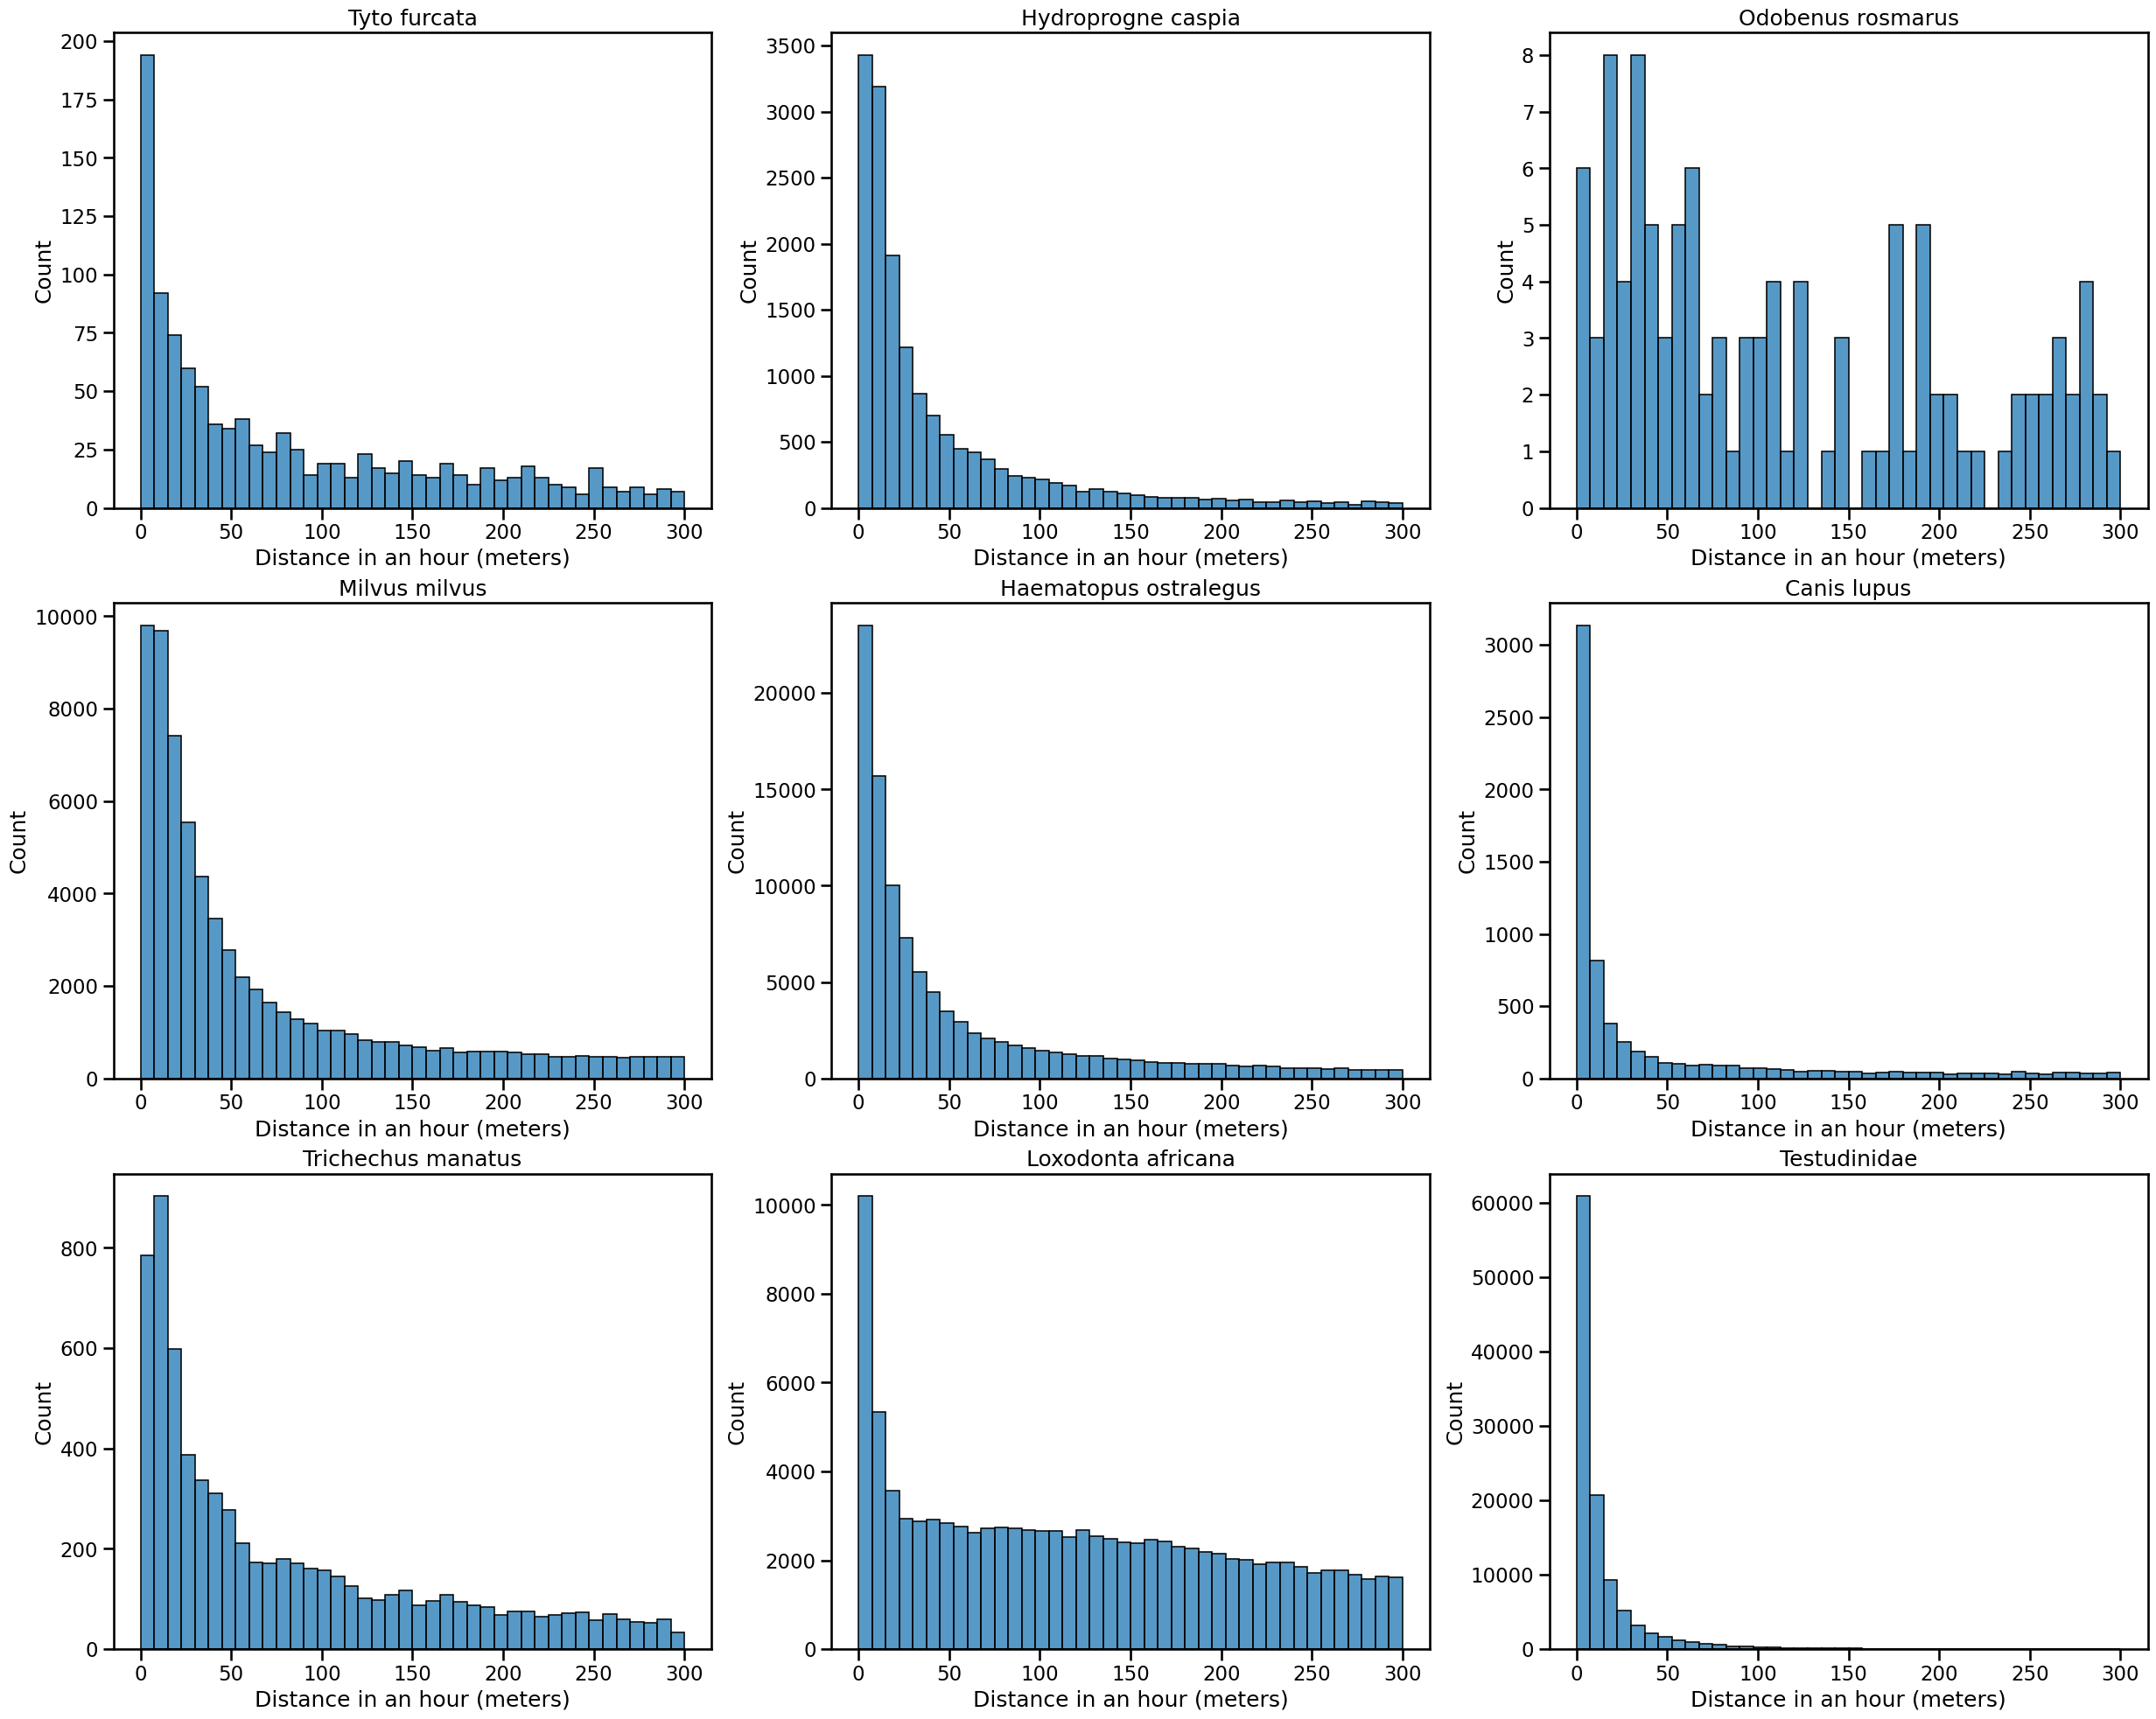

In [172]:
SPECIES_TO_SEE = [
'Tyto furcata', 'Hydroprogne caspia', 'Odobenus rosmarus',
       'Milvus milvus', 'Haematopus ostralegus', 'Canis lupus',
       'Trichechus manatus', 'Loxodonta africana', 'Testudinidae'
]

COLS = 3
fig, axs = plt.subplots(3, COLS, figsize=(30, 24))

for i, species in enumerate(SPECIES_TO_SEE):
    speeds = speeds_by_species[species]
    p = sns.histplot(speeds * 60 * 60, ax = axs[i//COLS][i%COLS], binrange=(0, 300), bins=40)
    p.set(xlabel="Distance in an hour (meters)", title=species)


In [175]:
step_percentiles[step_percentiles["species"].isin(SPECIES_TO_SEE)][
    ["species", "10_percentile_step", "20_percentile_step", "30_percentile_step"]]

,species,10_percentile_step,20_percentile_step,30_percentile_step
13,Tyto furcata,5.075252,13.907351,28.814733
17,Hydroprogne caspia,6.124363,11.611978,20.375915
40,Haematopus ostralegus,4.872966,10.245452,19.285831
42,Odobenus rosmarus,76.375779,267.538234,516.136937
54,Milvus milvus,9.515756,20.504946,39.359839
73,Canis lupus,2.136792,4.121769,7.682632
99,Trichechus manatus,9.037773,17.152603,32.624202
109,Loxodonta africana,22.130420,72.415449,125.635310
132,Testudinidae,0.942376,1.991297,3.093663
